In [ ]:
# ============================================================
# Stage 1: Data Cleaning, Preparation and Exploration
# Dataset: Breast Cancer Wisconsin (Diagnostic) - UCI
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder

# Make plots look cleaner
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

In [ ]:
# Load the original UCI file.
# We use the direct URL so the notebook is reproducible without manual upload.
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

# The original file has no header row, so we define column names manually.
columns = ['id', 'diagnosis'] + [f'feature_{i}' for i in range(1, 31)]
df = pd.read_csv(url, header=None, names=columns)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (569, 32)


,id,diagnosis,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,...,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
# ------------------------------------------------------------
# 1. Dataset description
# ------------------------------------------------------------
# The dataset has 569 samples and 30 numerical features.
# The target 'diagnosis' is binary: M (Malignant) or B (Benign).
# All features are continuous numeric values, no text data.
# ------------------------------------------------------------

print("Number of rows    :", df.shape[0])
print("Number of columns :", df.shape[1])
print("\nData types:\n", df.dtypes.value_counts())
print("\nTarget classes:\n", df['diagnosis'].value_counts())
print("\nMissing values per column:\n", df.isnull().sum().sum())

Number of rows    : 569
Number of columns : 32

Data types:
 float64    30
int64       1
object      1
Name: count, dtype: int64

Target classes:
 diagnosis
B    357
M    212
Name: count, dtype: int64

Missing values per column:
 0


In [ ]:
# ------------------------------------------------------------
# 2. Missing values, duplicates and irrelevant columns
# ------------------------------------------------------------

# Check for missing values
missing = df.isnull().sum().sum()
print("Total missing values:", missing)

# Check for duplicated rows
duplicates = df.duplicated().sum()
print("Duplicated rows:", duplicates)

# Drop duplicates if any
df = df.drop_duplicates()

# Drop the 'id' column because it is just an identifier, not a predictive feature.
df = df.drop('id', axis=1)

print("\nShape after cleaning:", df.shape)

Total missing values: 0
Duplicated rows: 0

Shape after cleaning: (569, 31)


In [ ]:
# ------------------------------------------------------------
# 3. Encoding the target variable
# ------------------------------------------------------------
# LabelEncoder converts M/B into 1/0 so the models can process it.
# M (Malignant) -> 1, B (Benign) -> 0
# ------------------------------------------------------------

le = LabelEncoder()
df['diagnosis'] = le.fit_transform(df['diagnosis'])

print("Encoded target values:")
print(df['diagnosis'].value_counts())

Encoded target values:
diagnosis
0    357
1    212
Name: count, dtype: int64


In [ ]:
# ------------------------------------------------------------
# 4. Handling outliers using the IQR method
# ------------------------------------------------------------
# Instead of deleting outlier rows, we replace them with the
# median. This keeps all 569 samples, which is important because
# SVM and Neural Networks are sensitive to extreme values.
# ------------------------------------------------------------

for col in df.columns[:-1]:   # skip the target column
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    median = df[col].median()
    df[col] = np.where(df[col] < lower, median, df[col])
    df[col] = np.where(df[col] > upper, median, df[col])

print("Outliers replaced with the median value.")
print("Remaining shape:", df.shape)

Outliers replaced with the median value.
Remaining shape: (569, 31)


In [ ]:
# ------------------------------------------------------------
# 5. Split features and target, then apply StandardScaler
# ------------------------------------------------------------
# Features have very different ranges (area in thousands vs.
# smoothness between 0 and 0.2). StandardScaler makes mean = 0
# and std = 1 so that no feature dominates the learning process.
# ------------------------------------------------------------

X = df.drop('diagnosis', axis=1)
y = df['diagnosis']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Convert back to DataFrame for easier EDA
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print("Shape of X_scaled:", X_scaled.shape)
X_scaled.describe().round(2).head()

Shape of X_scaled: (569, 30)


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_21,feature_22,feature_23,feature_24,feature_25,feature_26,feature_27,feature_28,feature_29,feature_30
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,...,0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.22,-2.35,-2.17,-1.73,-2.55,-1.80,-1.23,-1.33,-2.64,-2.09,...,-1.91,-2.31,-1.86,-1.52,-2.36,-1.65,-1.41,-1.75,-2.70,-1.60
25%,-0.70,-0.74,-0.70,-0.69,-0.73,-0.77,-0.78,-0.75,-0.73,-0.76,...,-0.68,-0.76,-0.70,-0.67,-0.71,-0.71,-0.78,-0.76,-0.68,-0.69


/tmp/ipykernel_667/824564502.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette='Set2')


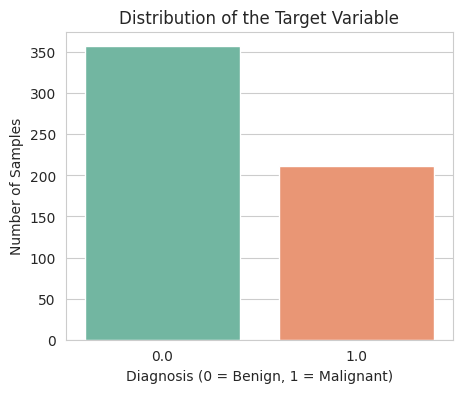

Benign cases   : 357
Malignant cases: 212


In [ ]:
# ------------------------------------------------------------
# 6.1 EDA: Target distribution
# ------------------------------------------------------------

plt.figure(figsize=(5, 4))
sns.countplot(x=y, palette='Set2')
plt.title('Distribution of the Target Variable')
plt.xlabel('Diagnosis (0 = Benign, 1 = Malignant)')
plt.ylabel('Number of Samples')
plt.show()

print("Benign cases   :", (y == 0).sum())
print("Malignant cases:", (y == 1).sum())

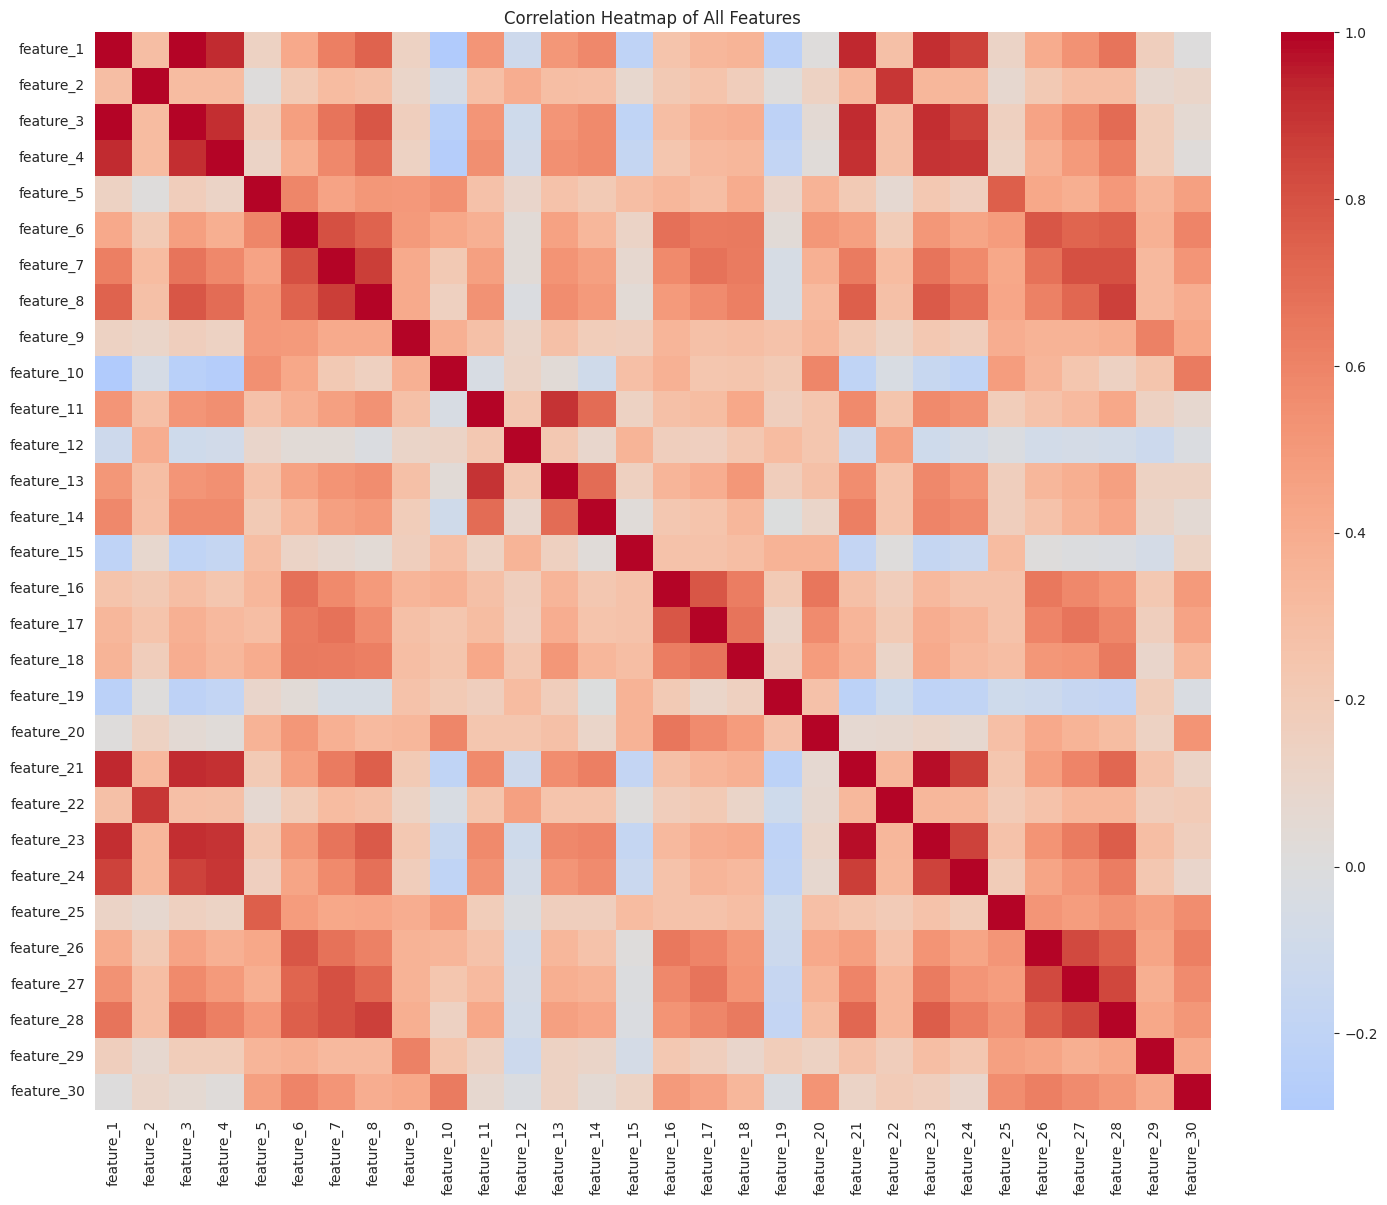

In [ ]:
# ------------------------------------------------------------
# 6.2 EDA: Correlation heatmap
# ------------------------------------------------------------

plt.figure(figsize=(18, 14))
sns.heatmap(X_scaled.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Heatmap of All Features')
plt.show()

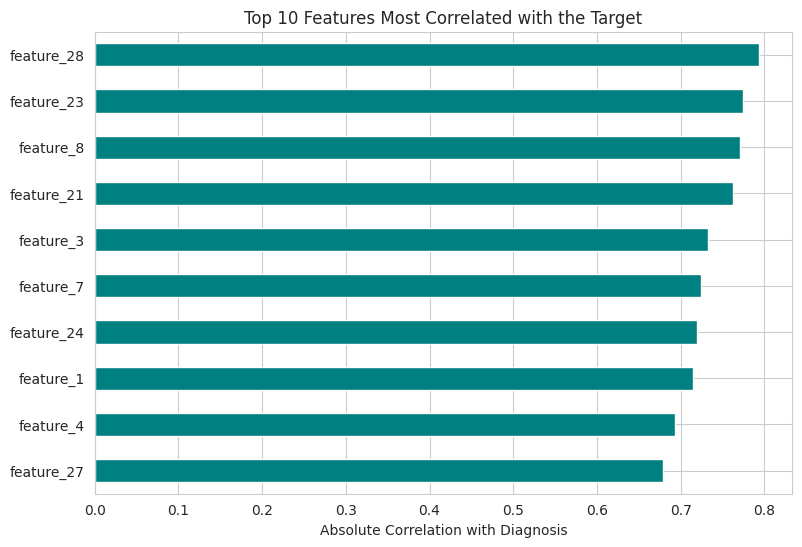

feature_28    0.794
feature_23    0.774
feature_8     0.771
feature_21    0.763
feature_3     0.732
feature_7     0.724
feature_24    0.720
feature_1     0.715
feature_4     0.693
feature_27    0.679
dtype: float64


In [ ]:
# ------------------------------------------------------------
# 6.3 EDA: Most relevant features for the target
# ------------------------------------------------------------

corr_target = X_scaled.corrwith(y).abs().sort_values(ascending=False)

plt.figure(figsize=(9, 6))
corr_target.head(10).plot(kind='barh', color='teal')
plt.gca().invert_yaxis()
plt.title('Top 10 Features Most Correlated with the Target')
plt.xlabel('Absolute Correlation with Diagnosis')
plt.show()

print(corr_target.head(10).round(3))

In [ ]:
# ------------------------------------------------------------
# 7. Summary of Stage 1 decisions
# ------------------------------------------------------------

summary = pd.DataFrame({
    'Step': [
        'Missing values',
        'Duplicates',
        'ID column',
        'Target encoding',
        'Outliers',
        'Scaling',
        'EDA',
        'Feature selection'
    ],
    'Decision': [
        'None found (verified)',
        'Removed if any',
        'Dropped',
        'LabelEncoder (M=1, B=0)',
        'Replaced with median (IQR)',
        'StandardScaler',
        'Countplot, Heatmap, Corr bar',
        'Top 10 correlated features noted'
    ],
    'Reason': [
        'Official dataset is clean',
        'Avoid data leakage',
        'ID is not predictive',
        'Models need numeric target',
        'Keep sample size (SVM/NN sensitive)',
        'Features have different ranges',
        'Understand patterns and target',
        'Guide model development'
    ]
})

print(summary.to_string(index=False))

             Step                         Decision                              Reason
   Missing values            None found (verified)           Official dataset is clean
       Duplicates                   Removed if any                  Avoid data leakage
        ID column                          Dropped                ID is not predictive
  Target encoding          LabelEncoder (M=1, B=0)          Models need numeric target
         Outliers       Replaced with median (IQR) Keep sample size (SVM/NN sensitive)
          Scaling                   StandardScaler      Features have different ranges
              EDA     Countplot, Heatmap, Corr bar      Understand patterns and target
Feature selection Top 10 correlated features noted             Guide model development
